# Phase 5: Job Description Text Analysis

**Author:** Beth Spornitz  
**Project:** NLP 02 - Text Preprocessing Custom

## Purpose

Compare the skills and terminology used in Data Analyst, Business Analyst, and Data Governance job descriptions.

## Research Question

Which words and skills appear most frequently in job descriptions for these three career paths?

## Approach

Collect four job descriptions for each role, apply text preprocessing, compare word frequencies, and visualize the results.

## Data

The dataset will contain 12 job descriptions:
- 4 Data Analyst
- 4 Business Analyst
- 4 Data Governance

Sources and collection dates will be documented.

In [4]:
from pathlib import Path

import polars as pl

# Locate the CSV file
data_path = Path("../data/job_descriptions.csv")

# Load the job-posting summaries
df = pl.read_csv(data_path)

# Check the dataset
print(f"Total job descriptions: {df.height}")
print("\nDescriptions by job category:")
print(df.group_by("role").len().sort("role"))

# Preview the data
df.head(5)

Total job descriptions: 12

Descriptions by job category:
shape: (3, 2)
┌──────────────────┬─────┐
│ role             ┆ len │
│ ---              ┆ --- │
│ str              ┆ u64 │
╞══════════════════╪═════╡
│ Business Analyst ┆ 4   │
│ Data Analyst     ┆ 4   │
│ Data Governance  ┆ 4   │
└──────────────────┴─────┘


role,job_title,employer,source_url,description
str,str,str,str,str
"""Data Analyst""","""Senior Data Analyst""","""ShyftLabs""","""https://jobs.lever.co/shyftlab…","""Develop Power BI dashboards an…"
"""Data Analyst""","""Data Analyst""","""Dun and Bradstreet""","""https://jobs.lever.co/dnb/c077…","""Develop Power BI dashboards an…"
"""Data Analyst""","""Staff Data Analyst""","""Mistplay""","""https://jobs.lever.co/mistplay…","""Use advanced SQL and Python fo…"
"""Data Analyst""","""BI Engineer Data Analyst""","""Apply Digital""","""https://jobs.lever.co/applydig…","""Develop dashboards and reporti…"
"""Business Analyst""","""Business Analyst""","""Avalere Health""","""https://jobs.lever.co/avalereh…","""Gather and document business r…"


In [7]:
from collections import Counter
import re

# Common stop words
stop_words = {
    "a",
    "an",
    "and",
    "are",
    "as",
    "at",
    "be",
    "but",
    "by",
    "for",
    "from",
    "has",
    "have",
    "in",
    "is",
    "it",
    "its",
    "of",
    "on",
    "or",
    "that",
    "the",
    "to",
    "was",
    "were",
    "will",
    "with",
}


def preprocess(text):
    """Clean and tokenize job description text for word frequency analysis."""
    # Convert to lowercase
    text = text.lower()

    # Remove punctuation
    text = re.sub(r"[^a-z0-9\s]", " ", text)

    # Split into tokens and remove stop words
    # Keep short technical terms such as AI, BI, and R
    tokens = [word for word in text.split() if word not in stop_words]

    return tokens


# Analyze each job category
role_frequencies = {}

for role in df["role"].unique().to_list():
    descriptions = df.filter(pl.col("role") == role)["description"].to_list()
    combined_text = " ".join(descriptions)

    tokens = preprocess(combined_text)
    role_frequencies[role] = Counter(tokens)

    print(f"\n{role}")
    print(f"Total cleaned tokens: {len(tokens)}")
    print("Top 10 words:")
    print(role_frequencies[role].most_common(10))


Business Analyst
Total cleaned tokens: 85
Top 10 words:
[('business', 6), ('requirements', 4), ('user', 4), ('document', 3), ('collaborate', 3), ('stakeholders', 3), ('develop', 3), ('acceptance', 3), ('testing', 3), ('system', 3)]

Data Analyst
Total cleaned tokens: 92
Top 10 words:
[('data', 5), ('develop', 4), ('dashboards', 4), ('sql', 4), ('power', 3), ('bi', 3), ('using', 3), ('python', 3), ('business', 3), ('reporting', 3)]

Data Governance
Total cleaned tokens: 88
Top 10 words:
[('data', 15), ('governance', 6), ('metadata', 4), ('quality', 4), ('support', 3), ('management', 3), ('coordinate', 3), ('lineage', 3), ('controls', 3), ('policies', 2)]


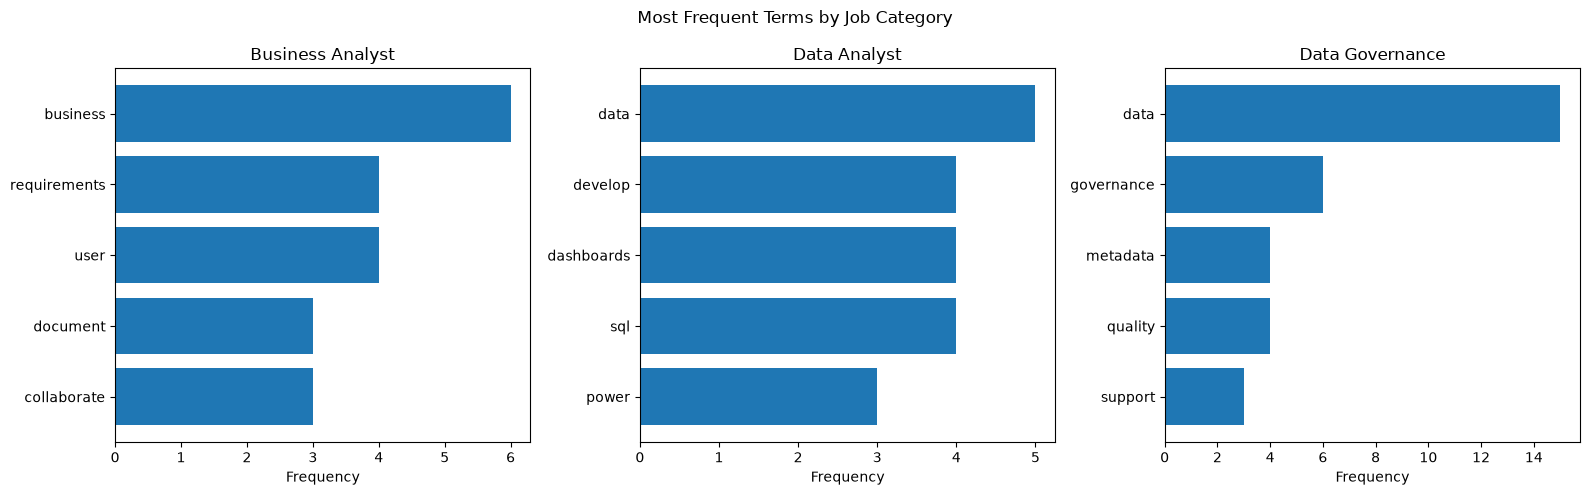

In [10]:
import matplotlib.pyplot as plt

roles = ["Business Analyst", "Data Analyst", "Data Governance"]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, role in zip(axes, roles):
    top_words = role_frequencies[role].most_common(5)

    words = [word for word, count in top_words]
    counts = [count for word, count in top_words]

    ax.barh(words[::-1], counts[::-1])
    ax.set_title(role)
    ax.set_xlabel("Frequency")

plt.suptitle("Most Frequent Terms by Job Category")
plt.tight_layout()

# Create the documentation images folder if needed
from pathlib import Path

image_path = Path("../docs/images")
image_path.mkdir(parents=True, exist_ok=True)

# Save the chart for GitHub Pages
plt.savefig(image_path / "job_description_comparison.png", dpi=150, bbox_inches="tight")

plt.show()

## Results and Observations

I analyzed 12 job posting summaries, with four examples each for Data Analyst, Business Analyst, and Data Governance positions.

The word frequency analysis revealed differences among the three categories:

- **Business Analyst:** Common terms - business, requirements, user, and stakeholders. These suggest an emphasis on gathering requirements, documenting processes, and working with stakeholders.
- **Data Analyst:** Common terms - data, dashboards, SQL, Python, and BI. These suggest a stronger emphasis on technical analysis, reporting, and visualization.
- **Data Governance:** Common terms - data, governance, metadata, quality, and lineage. These suggest an emphasis on data management, documentation, policies, and quality controls.

## Insights

The most interesting finding was how much the terminology was so different among the three job categories, even though all three involve working with data.  I was expecting them to be much more similar.

I also learned that preprocessing decisions are important.  Removing punctuation and filtering stop-words makes everything easier to compare, but these decisions must be made carefully so important information is not lost.

## Limitations

This analysis used 12 short summaries of job postings rather than complete job descriptions. The results reflect this small sample, not necessarily the broader job market.

## Next Steps

A future project could analyze more job postings and examine how job requirements change over time.